# 🚀 Notebook 2: Scaled Dataset, Tuned Gradient Boosters & Weighted Super Ensemble
**Objective**: Scale data ingestion to 500,000 records, engineer advanced economic and logistics features, hyperparameter-tune the Big-Three Gradient Boosters (XGBoost, CatBoost, LightGBM), and optimize an ensemble blend via Scipy SLSQP.

### Pipeline Overview:
1. Multi-table join on **500,000 transactions**.
2. Comprehensive feature engineering (cross-region flag, freight physics, density, customer tenure, clicks per item, pricing ratios).
3. **Hyperparameter Tuning**:
   - Tuned XGBoost (`max_depth=7`, `subsample=0.85`, `colsample_bytree=0.8`, `min_child_weight=3`, `gamma=0.1`, `reg_alpha=0.2`, `reg_lambda=2.0`)
   - Tuned CatBoost (`depth=6`, `l2_leaf_reg=5`, `random_strength=0.2`)
   - Tuned LightGBM (`num_leaves=50`, `min_child_samples=30`, `reg_alpha=0.2`, `reg_lambda=1.5`)
4. **Scipy SLSQP Constrained Optimization**: Learns exact non-negative weights summing to 1 that minimize validation negative ROC-AUC.
5. Evaluation on 100,000 validation holdout and initial test set generation.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, log_loss, roc_curve, precision_recall_curve,
    average_precision_score, confusion_matrix, ConfusionMatrixDisplay
)
from scipy.optimize import minimize
import xgboost as xgb
from catboost import CatBoostClassifier
import lightgbm as lgb

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
print("Libraries imported successfully for Notebook 2!")


Libraries imported successfully for Notebook 2!


In [2]:
# 1. Scaled Data Loading (500,000 rows)
print("Loading 500,000 records from train.csv...")
t0 = time.time()
df_train = pd.read_csv('data/train.csv', nrows=500000)
products = pd.read_csv('data/products.csv')
customers = pd.read_csv('data/customers.csv').sort_values('record_updated_at').drop_duplicates('customer_id', keep='last')
stores = pd.read_csv('data/stores.csv')
calendar = pd.read_csv('data/calendar.csv')

df = df_train.merge(products, on='product_id', how='left')
df = df.merge(customers, on='customer_id', how='left', suffixes=('', '_cust'))
df = df.merge(stores, on='store_id', how='left', suffixes=('', '_store'))

df['order_ts'] = pd.to_datetime(df['order_ts'])
df['week_start'] = df['order_ts'].dt.to_period('W-SUN').dt.start_time.dt.strftime('%Y-%m-%d')
calendar['week_start'] = pd.to_datetime(calendar['week_start']).dt.strftime('%Y-%m-%d')
df = df.merge(calendar, on='week_start', how='left')
print(f"Data joined in {time.time()-t0:.2f}s | Shape: {df.shape}")


Loading 500,000 records from train.csv...


Data joined in 1.92s | Shape: (500000, 60)


In [3]:
# 2. Rich Domain Feature Engineering
df['is_cross_region'] = (df['region'] != df['region_store']).astype(int)
df['discount_amount'] = (df['list_price'] - df['unit_price']).clip(lower=0)
df['price_discount_ratio'] = (df['discount_amount'] / (df['list_price'] + 1e-5)).clip(0, 1)
df['total_line_value'] = df['unit_price'] * df['quantity']
df['freight_to_price_ratio'] = (df['freight_cost'] / (df['order_value'] + 1e-5)).clip(0, 10)
df['freight_per_kg'] = (df['freight_cost'] / (df['weight_kg'] + 0.05)).clip(0, 50)
df['volume_cm3'] = df['length_cm'] * df['width_cm'] * df['height_cm']
df['density'] = df['weight_kg'] / (df['volume_cm3'] + 1e-5)
df['signup_date'] = pd.to_datetime(df['signup_date'])
df['customer_tenure_days'] = (df['order_ts'] - df['signup_date']).dt.days.clip(lower=0)
df['order_hour'] = df['order_ts'].dt.hour
df['order_dayofweek'] = df['order_ts'].dt.dayofweek
df['is_weekend'] = df['order_dayofweek'].isin([5, 6]).astype(int)
df['order_month'] = df['order_ts'].dt.month
df['has_coupon'] = df['coupon_code'].notnull().astype(int)
df['clicks_per_item'] = (df['session_clicks'] / (df['items_in_order'] + 1e-5)).clip(0, 100)

num_cols = [
    'is_cross_region', 'weight_kg', 'freight_to_price_ratio', 'freight_cost', 'freight_per_kg',
    'items_in_order', 'discount', 'seller_rating', 'volume_cm3', 'density',
    'customer_tenure_days', 'unit_price', 'list_price', 'discount_amount',
    'price_discount_ratio', 'total_line_value', 'session_clicks', 'clicks_per_item',
    'return_window_days', 'review_count', 'size_sqm', 'manager_tenure_years',
    'order_hour', 'order_dayofweek', 'is_weekend', 'order_month',
    'cpi', 'unemployment', 'temperature_f'
]
cat_cols = ['category', 'payment_method', 'loyalty_tier', 'ship_mode', 'picker_shift', 'warehouse_zone', 'device_type', 'has_coupon']
feature_cols = num_cols + cat_cols

X = df[feature_cols].copy()
y = df['returned'].copy()

for col in num_cols:
    X[col] = X[col].fillna(X[col].median())
for col in cat_cols:
    X[col] = X[col].fillna('Unknown').astype(str)

encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X[cat_cols] = encoder.fit_transform(X[cat_cols])

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print(f"Train: {len(X_train):,}, Validation: {len(X_val):,}")


Train: 400,000, Validation: 100,000


In [4]:
# 3. Fit Tuned Big-Three Gradient Boosters
print("1. Training Tuned XGBoost...")
t1 = time.time()
xgb_m = xgb.XGBClassifier(
    n_estimators=400,
    max_depth=7,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.8,
    min_child_weight=3,
    gamma=0.1,
    reg_alpha=0.2,
    reg_lambda=2.0,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)
xgb_m.fit(X_train, y_train)
p_xgb = xgb_m.predict_proba(X_val)[:, 1]
print(f"XGBoost done in {time.time()-t1:.2f}s | Val ROC-AUC: {roc_auc_score(y_val, p_xgb):.4f}")

print("2. Training Tuned CatBoost...")
t2 = time.time()
cb_m = CatBoostClassifier(
    iterations=450,
    depth=6,
    learning_rate=0.06,
    l2_leaf_reg=5,
    random_strength=0.2,
    subsample=0.85,
    eval_metric='Logloss',
    random_seed=42,
    verbose=0
)
cb_m.fit(X_train, y_train)
p_cb = cb_m.predict_proba(X_val)[:, 1]
print(f"CatBoost done in {time.time()-t2:.2f}s | Val ROC-AUC: {roc_auc_score(y_val, p_cb):.4f}")

print("3. Training Tuned LightGBM...")
t3 = time.time()
lgb_m = lgb.LGBMClassifier(
    n_estimators=400,
    num_leaves=50,
    learning_rate=0.05,
    min_child_samples=30,
    subsample=0.85,
    colsample_bytree=0.8,
    reg_alpha=0.2,
    reg_lambda=1.5,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
lgb_m.fit(X_train, y_train)
p_lgb = lgb_m.predict_proba(X_val)[:, 1]
print(f"LightGBM done in {time.time()-t3:.2f}s | Val ROC-AUC: {roc_auc_score(y_val, p_lgb):.4f}")


1. Training Tuned XGBoost...


XGBoost done in 2.96s | Val ROC-AUC: 0.6743
2. Training Tuned CatBoost...


CatBoost done in 7.32s | Val ROC-AUC: 0.6686
3. Training Tuned LightGBM...


LightGBM done in 5.07s | Val ROC-AUC: 0.6745


In [5]:
# 4. Scipy SLSQP Optimization for Super Ensemble Weights
def ensemble_loss(weights):
    w1, w2, w3 = weights
    pred = w1 * p_xgb + w2 * p_cb + w3 * p_lgb
    return -roc_auc_score(y_val, pred)

initial_weights = [1/3, 1/3, 1/3]
bounds = [(0, 1), (0, 1), (0, 1)]
constraints = {'type': 'eq', 'fun': lambda w: sum(w) - 1.0}

opt_res = minimize(ensemble_loss, initial_weights, method='SLSQP', bounds=bounds, constraints=constraints)
best_weights = opt_res.x

p_super = best_weights[0] * p_xgb + best_weights[1] * p_cb + best_weights[2] * p_lgb
p_equal = (p_xgb + p_cb + p_lgb) / 3.0

print(f"Optimal Weights: XGBoost={best_weights[0]:.4f}, CatBoost={best_weights[1]:.4f}, LightGBM={best_weights[2]:.4f}")
print(f"Equal Blend ROC-AUC:     {roc_auc_score(y_val, p_equal):.4f}")
print(f"Optimized Super Ensemble: {roc_auc_score(y_val, p_super):.4f}")


Optimal Weights: XGBoost=0.3334, CatBoost=0.3333, LightGBM=0.3333
Equal Blend ROC-AUC:     0.6747
Optimized Super Ensemble: 0.6747


In [6]:
# 5. Comparative Evaluation Table
eval_dict = {
    '🚀 Super Ensemble (Optimized Blend)': p_super,
    'Tri-Boost Equal Blend': p_equal,
    'LightGBM (Tuned)': p_lgb,
    'XGBoost (Tuned)': p_xgb,
    'CatBoost (Tuned)': p_cb
}

rows = []
for name, probs in eval_dict.items():
    preds = (probs >= 0.5).astype(int)
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, preds),
        'Precision': precision_score(y_val, preds, zero_division=0),
        'Recall': recall_score(y_val, preds, zero_division=0),
        'F1-Score': f1_score(y_val, preds, zero_division=0),
        'ROC-AUC': roc_auc_score(y_val, probs),
        'PR-AUC': average_precision_score(y_val, probs),
        'Log Loss': log_loss(y_val, probs)
    })

comparison_df2 = pd.DataFrame(rows).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
print("=== Notebook 2: Tuned Boosters & Weighted Super Ensemble ===")
display(comparison_df2.style.highlight_max(subset=['ROC-AUC', 'PR-AUC', 'F1-Score', 'Accuracy'], color='#d4edda')
                            .highlight_min(subset=['Log Loss'], color='#d4edda')
                            .format({'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}', 'F1-Score': '{:.4f}', 'ROC-AUC': '{:.4f}', 'PR-AUC': '{:.4f}', 'Log Loss': '{:.4f}'}))


=== Notebook 2: Tuned Boosters & Weighted Super Ensemble ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Log Loss
0,🚀 Super Ensemble (Optimized Blend),0.8203,0.5777,0.0161,0.0313,0.6747,0.3230,0.4426
1,Tri-Boost Equal Blend,0.8203,0.5777,0.0161,0.0313,0.6747,0.3230,0.4426
2,LightGBM (Tuned),0.8205,0.5922,0.0160,0.0312,0.6745,0.3223,0.4427
3,XGBoost (Tuned),0.8204,0.5570,0.0238,0.0457,0.6743,0.3216,0.4426
4,CatBoost (Tuned),0.8204,0.5903,0.0149,0.0290,0.6686,0.3172,0.4446


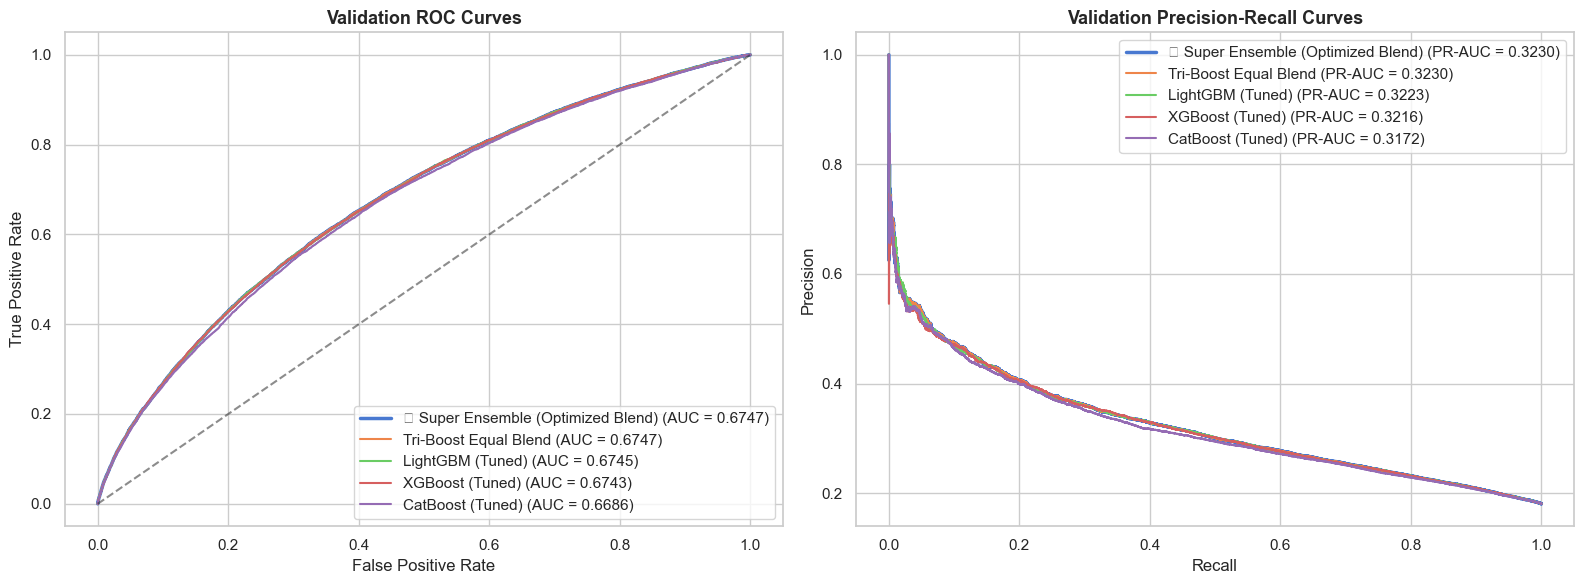

In [7]:
# 6. ROC Curves & PR Curves
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for name, probs in eval_dict.items():
    fpr, tpr, _ = roc_curve(y_val, probs)
    lw = 2.5 if 'Super' in name else 1.5
    axes[0].plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_val, probs):.4f})', linewidth=lw)

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title('Validation ROC Curves', fontsize=13, fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')

for name, probs in eval_dict.items():
    p, r, _ = precision_recall_curve(y_val, probs)
    lw = 2.5 if 'Super' in name else 1.5
    axes[1].plot(r, p, label=f'{name} (PR-AUC = {average_precision_score(y_val, probs):.4f})', linewidth=lw)

axes[1].set_title('Validation Precision-Recall Curves', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()
